# Bài 2: Hồi quy trên bộ dữ liệu Diabetes với các bộ feature khác nhau

**Sinh viên:** Nguyễn Đức Duy · **MSV:** 24174800068 · **Lớp:** DHKM18A2HN

So sánh 4 mô hình Linear Regression: `bmi`; `bmi + bp`; Top 5 feature theo tương quan; toàn bộ 10 feature. Đánh giá bằng MAE, RMSE, R².

## 1. Chuẩn bị dữ liệu

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

diabetes = load_diabetes(as_frame=True)
X = diabetes.data.copy()
y = diabetes.target.copy()

df = X.copy()
df["target"] = y
print("Kích thước dữ liệu:", df.shape)
print("Số giá trị thiếu:", df.isnull().sum().sum(), "| Số dòng trùng:", df.duplicated().sum())
df.head()

Kích thước dữ liệu: (442, 11)
Số giá trị thiếu: 0 | Số dòng trùng: 0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


## 2. Tương quan và chọn Top 5 feature

Tương quan với target (sắp theo |corr|):


,corr_with_target
bmi,0.586450
s5,0.565883
bp,0.441482
s4,0.430453
s3,-0.394789
s6,0.382483
s1,0.212022
age,0.187889
s2,0.174054
sex,0.043062


Top 5 feature: ['bmi', 's5', 'bp', 's4', 's3']


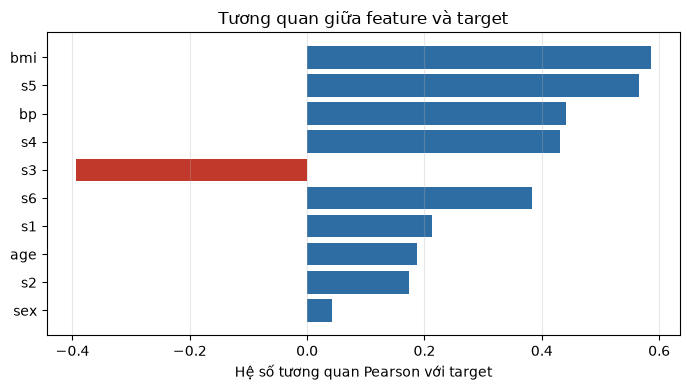

In [2]:
corr_t = df.corr()["target"].drop("target")
order = corr_t.abs().sort_values(ascending=False)
top5 = order.head(5).index.tolist()

print("Tương quan với target (sắp theo |corr|):")
display(corr_t.reindex(order.index).to_frame("corr_with_target"))
print("Top 5 feature:", top5)

c = corr_t.reindex(order.index)
plt.figure(figsize=(7, 4))
plt.barh(c.index[::-1], c.values[::-1], color=["#c0392b" if v < 0 else "#2e6da4" for v in c.values[::-1]])
plt.xlabel("Hệ số tương quan Pearson với target")
plt.title("Tương quan giữa feature và target")
plt.grid(alpha=.3, axis="x")
plt.tight_layout(); plt.show()

## 3. Chia train/test và huấn luyện 4 mô hình

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

sets = {
    "M1: bmi": ["bmi"],
    "M2: bmi + bp": ["bmi", "bp"],
    "M3: Top 5 tương quan": top5,
    "M4: Toàn bộ 10 feature": X.columns.tolist(),
}

kf = KFold(5, shuffle=True, random_state=42)
rows, preds, coefs = [], {}, {}
for name, cols in sets.items():
    m = LinearRegression().fit(X_train[cols], y_train)
    ptr, pte = m.predict(X_train[cols]), m.predict(X_test[cols])
    preds[name] = pte
    cv = cross_val_score(LinearRegression(), X[cols], y, cv=kf, scoring="r2")
    rows.append(dict(
        Model=name, n=len(cols),
        MAE_train=mean_absolute_error(y_train, ptr),
        RMSE_train=np.sqrt(mean_squared_error(y_train, ptr)),
        R2_train=r2_score(y_train, ptr),
        MAE=mean_absolute_error(y_test, pte),
        RMSE=np.sqrt(mean_squared_error(y_test, pte)),
        R2=r2_score(y_test, pte),
        CV_R2_mean=cv.mean(), CV_R2_std=cv.std()))
    coefs[name] = dict(zip(cols, m.coef_.round(2)), intercept=round(m.intercept_, 2))

res = pd.DataFrame(rows)
# Mốc tham chiếu: luôn dự đoán giá trị trung bình của tập train
base = np.full(len(y_test), y_train.mean())
print(f"Tham chiếu (đoán trung bình): MAE={mean_absolute_error(y_test, base):.2f}, "
      f"RMSE={np.sqrt(mean_squared_error(y_test, base)):.2f}, R2={r2_score(y_test, base):.4f}")

Tham chiếu (đoán trung bình): MAE=64.01, RMSE=73.22, R2=-0.0120


## 4. So sánh kết quả

In [4]:
display(res[["Model", "n", "MAE", "RMSE", "R2"]].round(4))          # tập test
display(res[["Model", "MAE_train", "MAE", "R2_train", "R2", "CV_R2_mean", "CV_R2_std"]].round(4))

,Model,n,MAE,RMSE,R2
0,M1: bmi,1,52.2600,63.7325,0.2334
1,M2: bmi + bp,2,50.0441,61.1597,0.2940
2,M3: Top 5 tương quan,5,43.9283,54.1893,0.4458
3,M4: Toàn bộ 10 feature,10,42.7941,53.8534,0.4526


,Model,MAE_train,MAE,R2_train,R2,CV_R2_mean,CV_R2_std
0,M1: bmi,51.3797,52.2600,0.3657,0.2334,0.3207,0.0776
1,M2: bmi + bp,48.9593,50.0441,0.4161,0.2940,0.3736,0.0710
2,M3: Top 5 tương quan,45.1304,43.9283,0.5012,0.4458,0.4570,0.0869
3,M4: Toàn bộ 10 feature,43.4835,42.7941,0.5279,0.4526,0.4785,0.0850


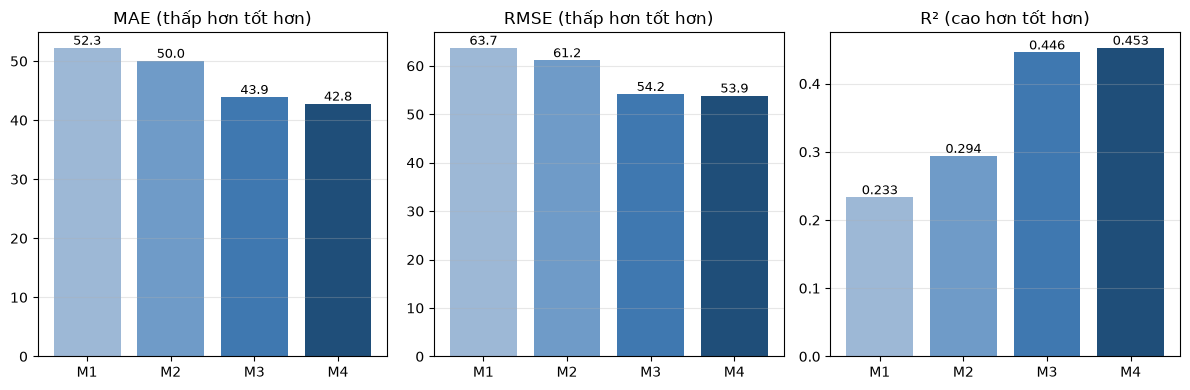

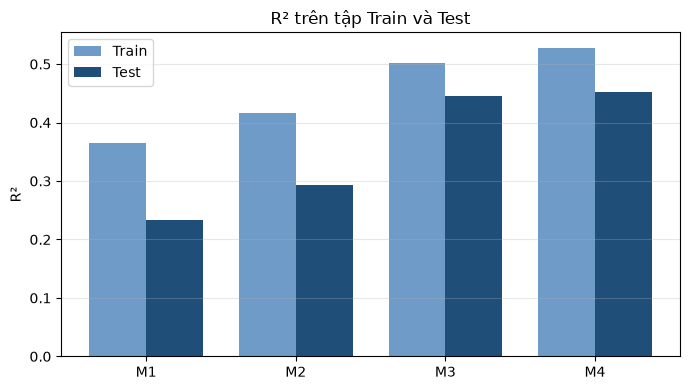

,bmi,intercept,bp,s5,s4,s3,age,sex,s1,s2,s6
M1: bmi,998.58,152.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
M2: bmi + bp,839.52,151.82,393.45,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
M3: Top 5 tương quan,602.37,151.49,299.52,488.57,-157.99,-318.45,NaN,NaN,NaN,NaN,NaN
M4: Toàn bộ 10 feature,542.43,151.35,347.70,736.20,275.32,163.42,37.9,-241.96,-931.49,518.06,48.67


In [5]:
labs = ["M1", "M2", "M3", "M4"]
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, (k, t) in zip(ax, [("MAE", "MAE (thấp hơn tốt hơn)"), ("RMSE", "RMSE (thấp hơn tốt hơn)"), ("R2", "R² (cao hơn tốt hơn)")]):
    b = a.bar(labs, res[k], color=["#9db8d6", "#6f9bc8", "#3f78b0", "#1f4e79"])
    a.set_title(t); a.grid(alpha=.3, axis="y")
    for r, v in zip(b, res[k]):
        a.text(r.get_x() + r.get_width()/2, v, f"{v:.3f}" if k == "R2" else f"{v:.1f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

fig, a = plt.subplots(figsize=(7, 4)); x = np.arange(4); w = .38
a.bar(x - w/2, res.R2_train, w, label="Train", color="#6f9bc8")
a.bar(x + w/2, res.R2, w, label="Test", color="#1f4e79")
a.set_xticks(x); a.set_xticklabels(labs); a.set_ylabel("R²")
a.set_title("R² trên tập Train và Test"); a.legend(); a.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()

pd.DataFrame(coefs).T

## 5. Chẩn đoán mô hình (Actual vs Predicted, Residual)

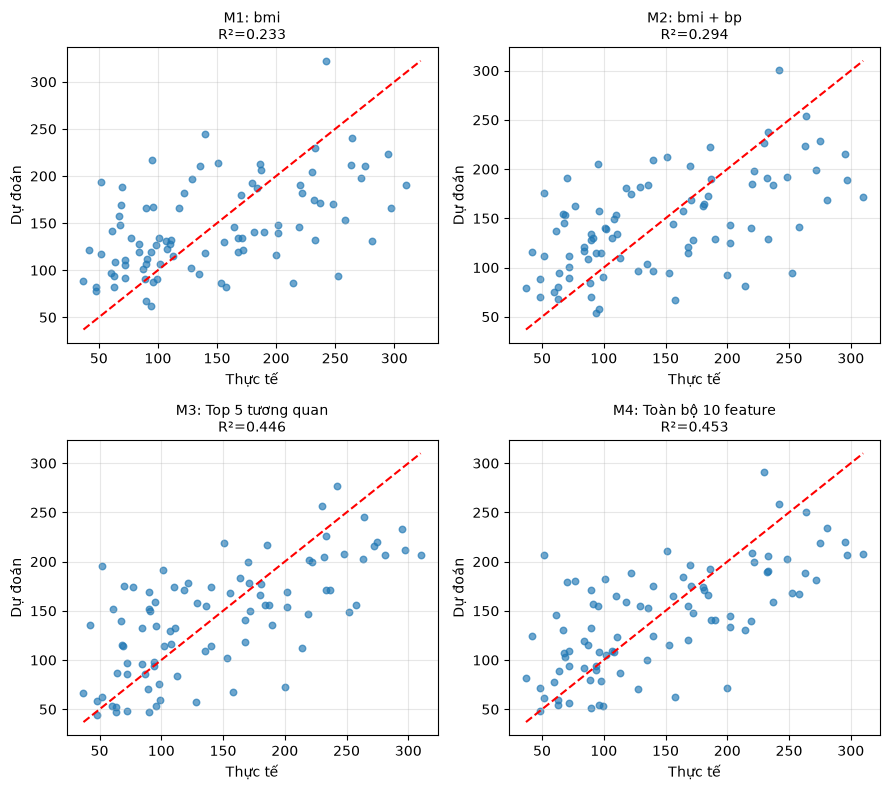

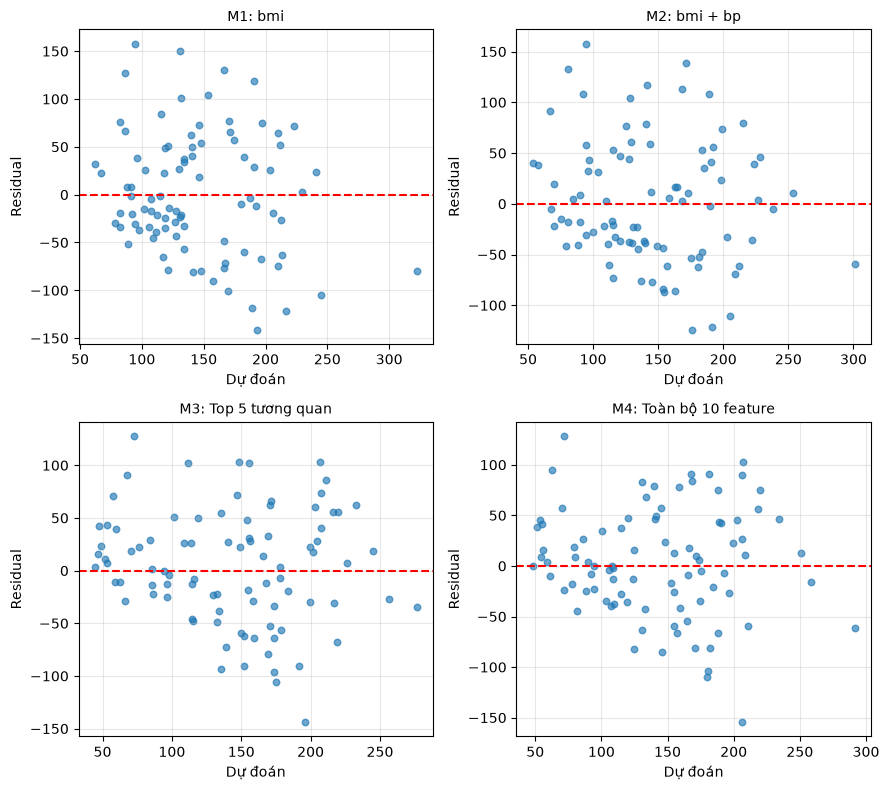

In [6]:
fig, ax = plt.subplots(2, 2, figsize=(9, 8))
for a, (n, p) in zip(ax.ravel(), preds.items()):
    a.scatter(y_test, p, alpha=.65, s=22)
    lo, hi = min(y_test.min(), p.min()), max(y_test.max(), p.max())
    a.plot([lo, hi], [lo, hi], "--", c="r")
    a.set_title(f"{n}\nR²={r2_score(y_test, p):.3f}", fontsize=10)
    a.set_xlabel("Thực tế"); a.set_ylabel("Dự đoán"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(2, 2, figsize=(9, 8))
for a, (n, p) in zip(ax.ravel(), preds.items()):
    a.scatter(p, y_test.values - p, alpha=.65, s=22)
    a.axhline(0, ls="--", c="r"); a.set_title(n, fontsize=10)
    a.set_xlabel("Dự đoán"); a.set_ylabel("Residual"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 6. Nhận xét

- **Thêm feature giúp mô hình tốt dần:** M1 < M2 < M3 ≲ M4 theo cả MAE, RMSE và R² (R² test lần lượt ≈ 0,233; 0,294; 0,446; 0,453).
- **Bước nhảy lớn nhất** là từ M2 lên M3, khi thêm các chỉ số máu `s5`, `s4`, `s3`.
- **Top 5 gần bằng 10 feature** (R² chênh ≈ 0,007, nhỏ hơn độ lệch chuẩn giữa các fold CV ≈ 0,085) nhưng gọn hơn. Ở M4, hệ số của `s1` và `s2` rất lớn và trái dấu → dấu hiệu đa cộng tuyến.
- **Không có overfitting rõ rệt**: R² train và test không chênh nhiều, CV cho thứ hạng giống nhau. Hạn chế chính là mô hình tuyến tính còn yếu (R² < 0,55 kể cả trên train).
- **Phần dư:** mô hình dự đoán thấp hơn thực tế với bệnh nhân nặng và cao hơn với bệnh nhân nhẹ → có thể có quan hệ phi tuyến. Hướng cải thiện: Feature Engineering, Ridge, Decision Tree, SVR, Gradient Boosting (Bài 3, Bài 4).
- *Lưu ý:* Top 5 được chọn bằng tương quan trên toàn bộ dữ liệu (theo slide); chặt chẽ hơn nên tính chỉ trên tập train.